In [1]:
%run ./01_load_and_process.ipynb

2016-06-01T00:00:08.184 2021-02-28T23:59:09.184 2016-06-01T00:05:00.000 2021-02-28T23:55:00.000


Displaying the entire integrate intensity of our subject of interest

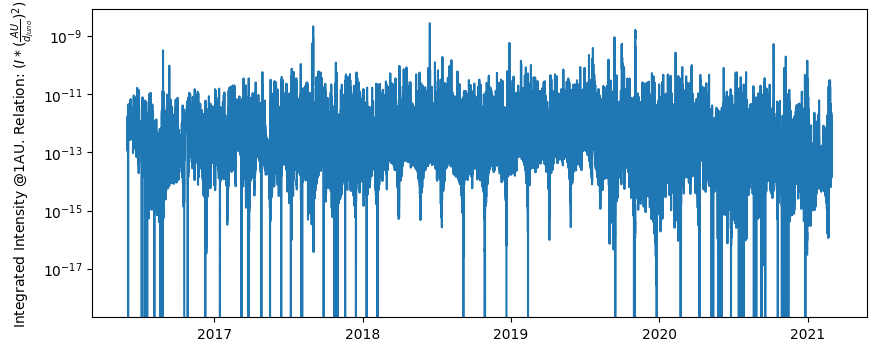

In [3]:
fig = plt.figure(figsize=(10,4))

plt.plot(time_datetime, (normalized_integrated_intensity_bKOM)*377)#*pow((AU/(df_juno_min["dist_RJ"]* RJ)), -2))
plt.ylabel('Integrated Intensity @1AU. Relation: $(I * (\\frac{AU}{d_{juno}})^2)$')

plt.yscale('log')
plt.show()

## Interaction of Solar wind and Jovian magnetosphere

(A) Data representation

In [4]:
import numpy as np

# A.0 Analysis interval

start = pd.Timestamp("2016-12-15 00:00:00")
end   = pd.Timestamp("2016-12-24 22:00:00")

In [5]:
# A.1 Build Juno bKOM + distance dataframe
df_juno_min = pd.DataFrame({"time": pd.to_datetime(time_over_year_sec, unit="s"), "intensity_raw": normalized_integrated_intensity_bKOM, "dist_RJ": obdist})
df_juno_min = df_juno_min.set_index("time").sort_index()

# Replace non-physical intensity values with NaN
df_juno_min["intensity"] = df_juno_min["intensity_raw"].where(df_juno_min["intensity_raw"] > 0, np.nan)

# Slice minute-level data
df_juno_min_subset = df_juno_min.loc[start:end].copy()

# A.2 Hourly resampling
df_hourly = pd.DataFrame()

df_hourly["intensity"] = (df_juno_min["intensity"].resample("1H").mean())
df_hourly["dist"] = (df_juno_min["dist_RJ"].resample("1H").mean())
df_hourly1 = df_hourly.loc[start:end].copy()

# A.3 Data-quality checks
raw_subset = df_juno_min.loc[start:end, "intensity_raw"]
n_total = len(raw_subset)
n_zero = (raw_subset == 0).sum()

print("\n--- Juno bKOM quality check ---")
print(f"Total minute samples      : {n_total}")
print(f"Zero samples              : {n_zero}")
print(f"Zero fraction             : {100*n_zero/n_total:.2f}%")



--- Juno bKOM quality check ---
Total minute samples      : 14280
Zero samples              : 0
Zero fraction             : 0.00%


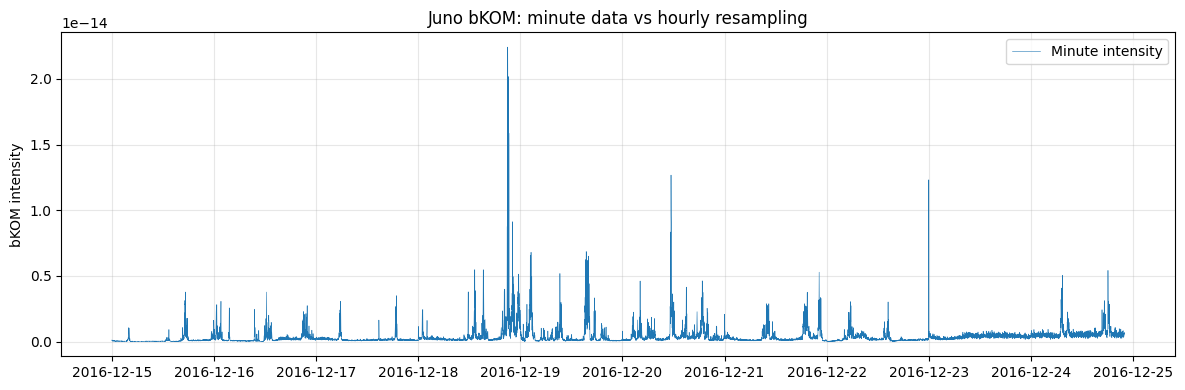

In [12]:
# A.4 Resampling sanity plot
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(df_juno_min_subset.index, df_juno_min_subset["intensity"], lw=0.4, label="Minute intensity")
#ax.plot(df_hourly1.index, df_hourly1["intensity"], lw=1.8, color="black", label="Hourly mean")

#ax.set_yscale("log")
ax.set_ylabel("bKOM intensity")
ax.set_title("Juno bKOM: minute data vs hourly resampling")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# A.5 MMESH variables
P_dyn = MMESH_slicing(start, end, "P_dyn")
B_mag = MMESH_slicing(start, end, "B_mag")
u_mag = MMESH_slicing(start, end, "u_mag")
n_tot = MMESH_slicing(start, end, "n_tot")

timestamps = MMESH_slicing(start, end, "1").index

print("\n--- MMESH cadence check ---")
print(P_dyn.index.to_series().diff().value_counts().head())

print("\nMMESH ranges:")
print("P_dyn:", P_dyn.min(), P_dyn.max())
print("B_mag:", B_mag.min(), B_mag.max())
print("u_mag:", u_mag.min(), u_mag.max())
print("n_tot:", n_tot.min(), n_tot.max())

# A.6 Alignment check
df_align_check = pd.concat([df_hourly1["intensity"], P_dyn.rename("P_dyn"), B_mag.rename("B_mag"), u_mag.rename("u_mag"), n_tot.rename("n_tot")], axis=1)

print("\n--- Alignment check ---")
print(df_align_check.shape)


--- MMESH cadence check ---
datetime
0 days 01:00:00    238
Name: count, dtype: int64

MMESH ranges:
P_dyn: 0.0077 0.4768
B_mag: 0.1503 2.6441
u_mag: 379.2906 542.2573
n_tot: 0.0234 1.3968

--- Alignment check ---
(239, 5)


(B) JSE angles

In [16]:
# JSE reliability / geometry
JSE_VALID_RANGE = (-180, 180)


# B.1 Load JSE angle file
path_jse = "/obs/kkesri/code/data/output-jup_sw_da_2016.txt"

df_jse = pd.read_csv(path_jse, comment="#", sep=r"\s+",  names=["time", "angle"])
df_jse["time"] = pd.to_datetime(df_jse["time"])
df_jse = df_jse.set_index("time").sort_index()

# B.2 Clean JSE angle
df_jse["angle"] = df_jse["angle"].where(df_jse["angle"].between(*JSE_VALID_RANGE), np.nan)
df_jse["angle"] = df_jse["angle"].interpolate(method="time")

df_jse_subset = df_jse.loc[start:end].copy()

print("\n--- JSE angle check ---")
print(df_jse_subset.head())
print(df_jse_subset.tail())
print(df_jse_subset["angle"].describe())


--- JSE angle check ---
                      angle
time                       
2016-12-15 00:00:00 -133.29
2016-12-15 01:00:00 -133.28
2016-12-15 02:00:00 -133.27
2016-12-15 03:00:00 -133.27
2016-12-15 04:00:00 -133.26
                      angle
time                       
2016-12-24 18:00:00 -92.218
2016-12-24 19:00:00 -92.148
2016-12-24 20:00:00 -92.079
2016-12-24 21:00:00 -92.005
2016-12-24 22:00:00 -91.929
count    239.000000
mean    -114.710431
std       13.626827
min     -133.290000
25%     -127.410000
50%     -116.310000
75%     -102.605000
max      -91.929000
Name: angle, dtype: float64


(C) Identifying the MMESH events

In [17]:
# Parameters
SMOOTH = 3
PLATEAU_FRACTION = 0.9
MIN_EVENT_DURATION = 3

# ID:: 0=P_dyn, 1=B_mag, 2=n_tot, 3=u_mag
ID = 0 
PAR = [P_dyn, B_mag, n_tot, u_mag] # parameters

# User-defined case. 0: default case, i.e., 95 %ile, 1: strict value (mean, median, or any certain value)
CASE = 1

In [18]:
# Depending on the case value, the code will either take derivatioves or will work with a concrete value
PAR_smooth = PAR[ID].rolling(SMOOTH, center=True, min_periods=1).mean()

if CASE == 1 :
    dPAR = PAR_smooth.diff()
    positive_dPAR = dPAR[dPAR > 0].dropna()
    PAR_DERIV_THRESHOLD = positive_dPAR.quantile(0.90)
    PAR_VALUE_THRESHOLD = PAR[ID].mean()

    rising = ( dPAR > PAR_DERIV_THRESHOLD ) & (PAR_smooth > PAR_VALUE_THRESHOLD)

# Main loop
forcing_records = []
in_forcing = False
forcing_start = None

for t in rising.index:

    if rising.loc[t] and not in_forcing:
        in_forcing = True
        forcing_start = t

    elif (not rising.loc[t]) and in_forcing:

        forcing_rise_end = t
        forcing_rise_duration_hr = (forcing_rise_end - forcing_start).total_seconds() / 3600

        if forcing_rise_duration_hr >= MIN_EVENT_DURATION:

            rise_end_value = PAR_smooth.asof(forcing_rise_end)
            plateau_threshold = PLATEAU_FRACTION * rise_end_value

            after_rise = PAR_smooth.loc[forcing_rise_end:]
            forcing_plateau_end = after_rise.index[-1]

            for tt, val in after_rise.items():
                if val < plateau_threshold:
                    forcing_plateau_end = tt
                    break

            forcing_window = PAR_smooth.loc[forcing_start:forcing_plateau_end]

            forcing_peak_time = forcing_window.idxmax()
            forcing_peak_value = forcing_window.max()
            forcing_midpoint = (forcing_start + (forcing_rise_end - forcing_start) / 2)

            forcing_plateau_duration_hr = (forcing_plateau_end - forcing_rise_end).total_seconds() / 3600
            forcing_duration_hr = (forcing_plateau_end - forcing_start).total_seconds() / 3600

            forcing_records.append({
                "forcing_start": forcing_start,
                "forcing_rise_end": forcing_rise_end,
                "forcing_midpoint": forcing_midpoint,
                "forcing_peak_time": forcing_peak_time,
                "forcing_peak_value": forcing_peak_value,
                "forcing_plateau_end": forcing_plateau_end,
                "forcing_rise_duration_hr": forcing_rise_duration_hr,
                "forcing_plateau_duration_hr": forcing_plateau_duration_hr,
                "forcing_duration_hr": forcing_duration_hr,
                "plateau_threshold": plateau_threshold,
                "rise_end_value": rise_end_value,
            })

        in_forcing = False

df_forcing = pd.DataFrame(forcing_records)

if not df_forcing.empty:
    df_forcing = df_forcing.set_index("forcing_midpoint")

print(df_forcing["forcing_start"])


forcing_midpoint
2016-12-18 23:30:00   2016-12-18 21:00:00
Name: forcing_start, dtype: datetime64[ns]


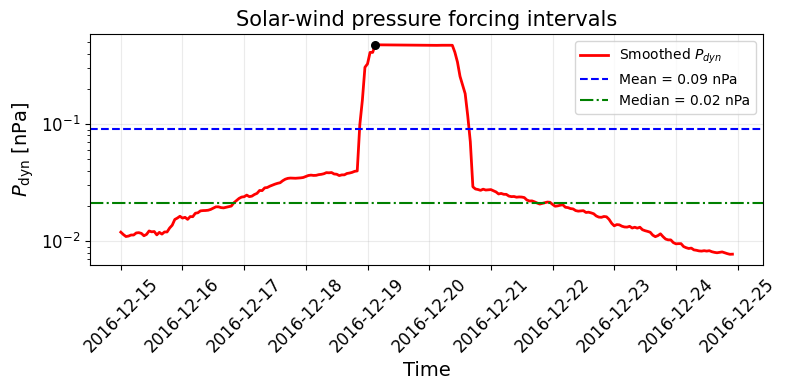

In [19]:
P_mean = P_dyn.mean()
P_median = P_dyn.median()

fig, ax = plt.subplots(figsize=(8, 4), sharex=True)

# ---------------- P_dyn ----------------
#ax.plot(P_dyn.index, P_dyn, color="lightcoral", lw=1,
    #       label="Raw $P_{dyn}$")
ax.plot(PAR_smooth.index, PAR_smooth, color="red", lw=2,
           label="Smoothed $P_{dyn}$")

for t_mid, row in df_forcing.iterrows():
    ax.scatter(row["forcing_peak_time"], row["forcing_peak_value"],
                  color="black", s=30, zorder=5)
    #ax.axvline(row["forcing_rise_end"])

ax.axhline(P_mean, color="blue", ls="--", lw=1.5,
              label=f"Mean = {P_mean:.2f} nPa")
ax.axhline(P_median, color="green", ls="-.", lw=1.5,
              label=f"Median = {P_median:.2f} nPa")

ax.set_yscale("log")
ax.set_ylabel(r"$P_{\rm dyn}$ [nPa]", fontsize=14)
ax.set_xlabel("Time", fontsize=14)
ax.set_title("Solar-wind pressure forcing intervals", fontsize=15)
ax.tick_params(labelsize=12)
ax.legend(fontsize=10)
ax.grid(alpha=0.25)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


(D) Find bKOM response + gaussian envelope to find the active duration

In [20]:
# bKOM response search
BKOM_SEARCH_WINDOW = 36       # ± hours around P_dyn event midpoint

# Envelope variables
ENVELOPE_WINDOW = 10
ENVELOPE_QUANTILE = 0.90

# Gaussian variables
FIT_WINDOW_BEFORE = 70
FIT_WINDOW_AFTER  = 70
MAX_ACTIVE_DURATION_HR = FIT_WINDOW_BEFORE + FIT_WINDOW_AFTER
MAX_SIGMA_HR = MAX_ACTIVE_DURATION_HR / 4
T0_BOUND = 36   # Gaussian centre allowed within ±36 h of burst peak

MIN_FIT_POINTS = 1

In [21]:
from scipy.optimize import curve_fit
from scipy.signal import find_peaks

# Gaussian model
def gaussian_pulse(t, baseline, amp, t0, sigma_t):
    return baseline + amp * np.exp(-0.5 * ((t - t0) / sigma_t)**2)

# -----------------------------------------------------------------------------
# Main loop
# -----------------------------------------------------------------------------

bkom_results = []
used_response_times = []

for t_forcing, forcing_row in df_forcing.iterrows():

    # =========================================================================
    # LAYER 1: FIND bKOM BURST WITHIN ± BKOM_SEARCH_WINDOW
    # =========================================================================

    response_window = df_hourly.loc[
        t_forcing - pd.Timedelta(hours=BKOM_SEARCH_WINDOW):
        t_forcing + pd.Timedelta(hours=BKOM_SEARCH_WINDOW),
        "intensity"
    ].dropna()

    if len(response_window) < 5:
        continue

    logI_response = np.log10(response_window[response_window > 0]).dropna()

    if len(logI_response) < 5:
        continue

    dlogI = logI_response.diff()
    rising = dlogI > 0

    segments = []
    current_segment = []

    for t in rising.index:

        if rising.loc[t]:
            current_segment.append(t)

        else:
            if len(current_segment) > 1:
                segments.append(current_segment)
            current_segment = []

    if len(current_segment) > 1:
        segments.append(current_segment)

    if len(segments) == 0:
        continue

    # choose strongest log jump
    best_jump = -np.inf
    best_segment = None

    for seg in segments:

        t_start = seg[0]
        t_end   = seg[-1]

        jump = logI_response.loc[t_end] - logI_response.loc[t_start]

        if jump > best_jump:
            best_jump = jump
            best_segment = (t_start, t_end)

    burst_base, burst_peak = best_segment

    baseline_log = logI_response.loc[burst_base]
    peak_log     = logI_response.loc[burst_peak]

    jump_log = peak_log - baseline_log
    response_ratio = 10**jump_log

    burst_midpoint = burst_base + (burst_peak - burst_base) / 2

    burst_duration_hr = (burst_peak - burst_base).total_seconds() / 3600

    # avoid assigning same burst to nearby forcing events
    if any(
        abs((burst_midpoint - used).total_seconds() / 3600) < 6
        for used in used_response_times
    ):
        continue

    used_response_times.append(burst_midpoint)

    # Correct lag definitions
    lag_hours_peak = (burst_peak - forcing_row["forcing_rise_end"]).total_seconds() / 3600
    lag_hours_onset = (burst_base - forcing_row["forcing_start"]).total_seconds() / 3600
    lag_hours_midpoints = (burst_midpoint - t_forcing).total_seconds() / 3600

    # =========================================================================
    # LAYER 2: GAUSSIAN FIT TO ROLLING UPPER ENVELOPE
    # =========================================================================

    fit_window = df_hourly.loc[
        burst_peak - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
        burst_peak + pd.Timedelta(hours=FIT_WINDOW_AFTER),
        "intensity"
    ].dropna()

    logI_fit = np.log10(fit_window[fit_window > 0]).dropna()

    if len(logI_fit) < MIN_FIT_POINTS:

        fit_success = False

        active_start = burst_base
        active_end = burst_peak
        active_duration_hr = burst_duration_hr

        fit_baseline = np.nan
        fit_amp = np.nan
        fit_t0 = np.nan
        fit_sigma_hr = np.nan
        energy_proxy = np.nan

    else:
        # Defining the envelope, about two jovian rotations
        envelope = (logI_fit.rolling(ENVELOPE_WINDOW, center=True, min_periods=1).quantile(ENVELOPE_QUANTILE))
        t_hours = (envelope.index - burst_peak).total_seconds() / 3600
        y = envelope.values

        baseline_guess = np.nanpercentile(y, 20)
        amp_guess = np.nanmax(y) - baseline_guess

        if amp_guess <= 0:
            amp_guess = 0.1

        t0_guess = t_hours[np.nanargmax(y)]
        t0_guess = np.clip(t0_guess, -T0_BOUND + 0.01, T0_BOUND - 0.01)

        sigma_guess = 18.0
 
        p0 = [baseline_guess, amp_guess, t0_guess, sigma_guess]

        bounds = ([np.nanmin(y) - 1.0, 0.0, -T0_BOUND, 2.0],[np.nanmax(y) + 1.0, 5.0, T0_BOUND, MAX_SIGMA_HR])

        try:
            popt, pcov = curve_fit(gaussian_pulse, t_hours, y, p0=p0, bounds=bounds, maxfev=20000)
            fit_baseline, fit_amp, fit_t0, fit_sigma_hr = popt

            # Main active-duration definition: ±2 sigma
            active_start = burst_peak + pd.Timedelta(hours=fit_t0 - 2 * fit_sigma_hr)
            active_end = burst_peak + pd.Timedelta(hours=fit_t0 + 2 * fit_sigma_hr)

            active_duration_hr = 4 * fit_sigma_hr

            # Integral of Gaussian excess above baseline in log-space units
            response_area_log = 0.95 * fit_amp * fit_sigma_hr * np.sqrt(2 * np.pi)

            fit_success = True

            # Goodness of fit statistic, R^2 statistics.
            y_fit = gaussian_pulse(t_hours, *popt)
            ss_res = np.sum((y - y_fit)**2)
            ss_tot = np.sum((y - np.mean(y))**2)
            fit_r2 = 1 - ss_res / ss_tot

        except Exception:

            fit_success = False

            active_start = burst_base
            active_end = burst_peak
            active_duration_hr = burst_duration_hr

            fit_baseline = np.nan
            fit_amp = np.nan
            fit_t0 = np.nan
            fit_sigma_hr = np.nan
            response_area_log = np.nan

        # =========================================================================
        # PEAKS ABOVE GAUSSIAN HALF-MAXIMUM
        # =========================================================================

        active_logI = (np.log10(df_hourly.loc[active_start:active_end, "intensity"]).replace([np.inf, -np.inf], np.nan).dropna())

        if fit_success and len(active_logI) >= 3:
            # Half-maximum of fitted Gaussian ABOVE the fitted baseline
            half_max_level = fit_baseline + 0.5 * fit_amp
            fwhm_hr = (2 * np.sqrt(2 * np.log(2)) * fit_sigma_hr)

            # Find all local maxima
            peaks, _ = find_peaks(active_logI.values)

            # Keep only peaks above Gaussian half-maximum
            major_peaks = peaks[active_logI.values[peaks] >= half_max_level]

            n_peaks = len(major_peaks) # number of peaks within the gaussian fit

        else:

            half_max_level = np.nan
            n_peaks = np.nan

    # =========================================================================
    # Juno distance during active interval
    # =========================================================================

    dist_window = df_hourly.loc[active_start:active_end, "dist"].dropna()

    if len(dist_window) > 0:
        r_min_RJ = dist_window.min()
        r_max_RJ = dist_window.max()
        r_mean_RJ = dist_window.mean()
        r_std_RJ = dist_window.std()
    else:
        r_min_RJ = np.nan
        r_max_RJ = np.nan
        r_mean_RJ = np.nan
        r_std_RJ = np.nan

    # =========================================================================
    # STORE
    # =========================================================================

    bkom_results.append({
        "forcing_midpoint": t_forcing,

        # burst quantities
        "burst_base": burst_base,
        "burst_peak": burst_peak,
        "burst_midpoint": burst_midpoint,
        "burst_duration_hr": burst_duration_hr,

        # lag quantities
        "lag_hours_peak": lag_hours_peak,
        "lag_hours_onset": lag_hours_onset,
        "lag_hours_midpoints": lag_hours_midpoints,

        # response strength
        "baseline_log": baseline_log,
        "peak_log": peak_log,
        "jump_log": jump_log,
        "response_ratio": response_ratio,

        # active interval: ±2 sigma
        "active_start": active_start,
        "active_end": active_end,
        "active_duration_hr": active_duration_hr,

        # Gaussian fit
        "fit_success": fit_success,
        "fit_baseline_log": fit_baseline,
        "fit_amp_log": fit_amp,
        "fit_t0_hr": fit_t0,
        "fit_sigma_hr": fit_sigma_hr,
        "response_area_log": response_area_log,
        "fit_r2" : fit_r2,
        "fwhm_hr" : fwhm_hr,
        "half_max_log" : half_max_level,

        # Juno distance
        "r_min_RJ": r_min_RJ,
        "r_max_RJ": r_max_RJ,
        "r_mean_RJ": r_mean_RJ,
        "r_std_RJ": r_std_RJ,
        "n_peaks" : n_peaks,
    })


df_bkom = pd.DataFrame(bkom_results)

if not df_bkom.empty:
    df_bkom = df_bkom.set_index("forcing_midpoint")

#print(df_bkom)

In [93]:
# =============================================================================
# PART E — JOIN FORCING + BKOM RESPONSE
# =============================================================================

df_combined = df_forcing.join(df_bkom, how="inner")

In [22]:
PAIR_NUMBER = 1   # 1, 2, 3, ...

Plotting pair #1
Forcing midpoint: 2016-12-18 23:30:00


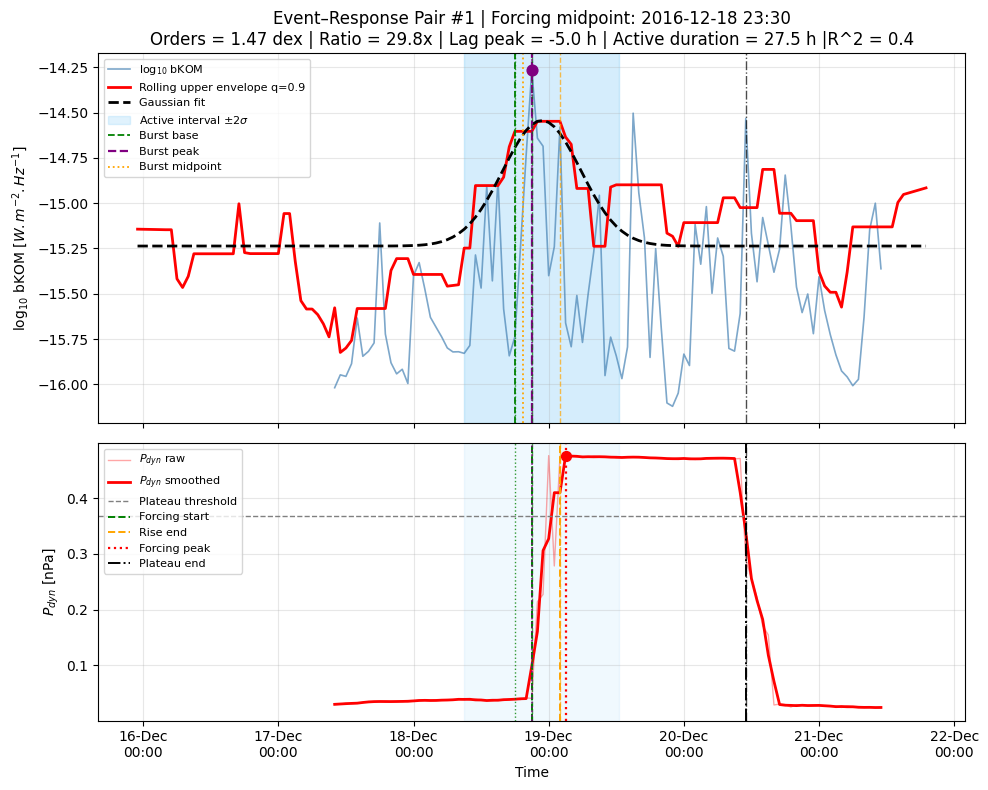

In [23]:
# EVENT–RESPONSE PAIR DIAGNOSTIC PLOT

import matplotlib.dates as mdates

df_pair_table = df_forcing.join(df_bkom, how="inner")

t_pair = df_pair_table.index[PAIR_NUMBER - 1]
row = df_pair_table.loc[t_pair]

print(f"Plotting pair #{PAIR_NUMBER}")
print("Forcing midpoint:", t_pair)

# -----------------------------------------------------------------------------
# Plot window
# -----------------------------------------------------------------------------

plot_start = min(row["forcing_start"], row["burst_base"], row["active_start"]) - pd.Timedelta(hours=24)
plot_end   = max(row["forcing_plateau_end"], row["burst_peak"], row["active_end"]) + pd.Timedelta(hours=24)

# -----------------------------------------------------------------------------
# Reconstruct bKOM log intensity, upper envelope, and Gaussian fit
# -----------------------------------------------------------------------------

i_plot = df_hourly.loc[plot_start:plot_end, "intensity"].dropna()
logI_plot = np.log10(i_plot[i_plot > 0]).dropna()

fit_window = df_hourly.loc[
    row["burst_peak"] - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
    row["burst_peak"] + pd.Timedelta(hours=FIT_WINDOW_AFTER),
    "intensity"
].dropna()

logI_fit = np.log10(fit_window[fit_window > 0]).dropna()
envelope = (logI_fit.rolling(ENVELOPE_WINDOW, center=True, min_periods=1).quantile(ENVELOPE_QUANTILE))

# Gaussian curve from saved fit parameters
if row["fit_success"]:

    t_hours_env = (envelope.index - row["burst_peak"]).total_seconds() / 3600
    gauss_y = gaussian_pulse(t_hours_env, row["fit_baseline_log"], row["fit_amp_log"], row["fit_t0_hr"], row["fit_sigma_hr"])

else:
    gauss_y = None

# -----------------------------------------------------------------------------
# Local MMESH/JSE slices
# -----------------------------------------------------------------------------

P_plot = P_dyn.loc[plot_start:plot_end]
P_smooth_plot = PAR_smooth.loc[plot_start:plot_end]

B_plot = B_mag.loc[plot_start:plot_end]
n_plot = n_tot.loc[plot_start:plot_end]
u_plot = u_mag.loc[plot_start:plot_end]

dist_plot = df_hourly.loc[plot_start:plot_end, "dist"]

if "df_jse" in globals():
    jse_plot = df_jse.loc[plot_start:plot_end, "angle"]
else:
    jse_plot = None

# -----------------------------------------------------------------------------
# Figure
# -----------------------------------------------------------------------------

n_panels = 2 if jse_plot is not None else 2

fig, axs = plt.subplots(
    n_panels, 1,
    figsize=(10, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1.6, 1.2, 1, 1, 1, 1][:n_panels]}
)

# =============================================================================
# Panel 1: bKOM response + envelope + Gaussian fit
# =============================================================================

ax = axs[0]

ax.plot(logI_plot.index, logI_plot.values, color="steelblue", lw=1.2, alpha=0.7, label=r"log$_{10}$ bKOM")
ax.plot(envelope.index, envelope.values, color="red", lw=2, label=f"Rolling upper envelope q={ENVELOPE_QUANTILE}")

if gauss_y is not None:
    ax.plot(envelope.index, gauss_y, color="black", lw=2, linestyle="--", label="Gaussian fit" )

ax.axvspan(row["active_start"], row["active_end"], color="lightskyblue", alpha=0.25, label=r"Active interval $\pm 2\sigma$")
ax.axvline(row["burst_base"], color="green", linestyle="--", lw=1.3, label="Burst base")
ax.axvline(row["burst_peak"], color="purple", linestyle="--", lw=1.6, label="Burst peak")
ax.axvline(row["burst_midpoint"], color="orange", linestyle=":", lw=1.3, label="Burst midpoint")

ax.scatter(row["burst_peak"], row["peak_log"], color="purple", s=60, zorder=5)

ax.set_ylabel(r"log$_{10}$ bKOM [$W. m^{-2} . Hz^{-1}$]")
ax.set_title(
    f"Event–Response Pair #{PAIR_NUMBER} | "
    f"Forcing midpoint: {t_pair.strftime('%Y-%m-%d %H:%M')}\n"
    f"Orders = {row['jump_log']:.2f} dex | "
    f"Ratio = {row['response_ratio']:.1f}x | "
    f"Lag peak = {row['lag_hours_peak']:.1f} h | "
    f"Active duration = {row['active_duration_hr']:.1f} h |"
    f"R^2 = {row['fit_r2']:.1f}"
)
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

# =============================================================================
# Panel 2: P_dyn forcing
# =============================================================================

ax = axs[1]

ax.plot(P_plot.index, P_plot.values, color="red", alpha=0.35, lw=1, label=r"$P_{dyn}$ raw")
ax.plot(P_smooth_plot.index, P_smooth_plot.values, color="red", lw=2, label=r"$P_{dyn}$ smoothed")

ax.axhline(
    row["plateau_threshold"],
    color="grey",
    linestyle="--",
    lw=1,
    label="Plateau threshold"
)

ax.axvline(row["forcing_start"], color="green", linestyle="--", lw=1.4, label="Forcing start")
ax.axvline(row["forcing_rise_end"], color="orange", linestyle="--", lw=1.4, label="Rise end")
ax.axvline(row["forcing_peak_time"], color="red", linestyle=":", lw=1.6, label="Forcing peak")
ax.axvline(row["forcing_plateau_end"], color="black", linestyle="-.", lw=1.4, label="Plateau end")

ax.scatter(
    row["forcing_peak_time"],
    row["forcing_peak_value"],
    color="red",
    s=50,
    zorder=5
)

ax.set_ylabel(r"$P_{dyn}$ [nPa]")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)


# -----------------------------------------------------------------------------
# Shared vertical markers on all panels
# -----------------------------------------------------------------------------

for ax in axs:

    ax.axvline(row["forcing_start"], color="green", linestyle="--", lw=1, alpha=0.7)
    ax.axvline(row["forcing_rise_end"], color="orange", linestyle="--", lw=1, alpha=0.7)
    ax.axvline(row["forcing_plateau_end"], color="black", linestyle="-.", lw=1, alpha=0.7)

    ax.axvline(row["burst_base"], color="green", linestyle=":", lw=1, alpha=0.8)
    ax.axvline(row["burst_peak"], color="purple", linestyle=":", lw=1.2, alpha=0.9)

    ax.axvspan(row["active_start"], row["active_end"], color="lightskyblue", alpha=0.12)

# -----------------------------------------------------------------------------
# X-axis formatting
# -----------------------------------------------------------------------------

axs[-1].set_xlabel("Time")
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b\n%H:%M"))

plt.tight_layout()
plt.show()


The following snippet is for the presentation generation for all the cases identified. Run it only in the case if you want to have a comprehensive slides with all the cases identified so far. 

In [ ]:
from pptx import Presentation
from pptx.util import Inches
from io import BytesIO
from tqdm.auto import tqdm
import matplotlib.dates as mdates

# =============================================================================
# SETTINGS
# =============================================================================

OUTPUT_PPTX = "Juno_bKOM_Event_Response_Pairs.pptx"

df_pair_table = df_forcing.join(df_bkom, how="inner").sort_index()

prs = Presentation()
prs.slide_width = Inches(13.333)
prs.slide_height = Inches(7.5)

blank_layout = prs.slide_layouts[6]

# =============================================================================
# GENERATE ONE SLIDE PER EVENT–RESPONSE PAIR
# =============================================================================

for pair_number, (t_pair, row) in enumerate(
    tqdm(df_pair_table.iterrows(), total=len(df_pair_table)),
    start=1
):

    # Time window
    plot_start = min(row["forcing_start"], row["burst_base"], row["active_start"]) - pd.Timedelta(hours=24)
    plot_end = max(row["forcing_plateau_end"],  row["burst_peak"], row["active_end"]) + pd.Timedelta(hours=24)

    # bKOM data and Gaussian
    i_plot = df_hourly.loc[plot_start:plot_end, "intensity"].dropna()
    logI_plot = np.log10(i_plot[i_plot > 0]).dropna()

    fit_window = df_hourly.loc[
        row["burst_peak"] - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
        row["burst_peak"] + pd.Timedelta(hours=FIT_WINDOW_AFTER),
        "intensity"
    ].dropna()

    logI_fit = np.log10(fit_window[fit_window > 0]).dropna()

    envelope = (logI_fit.rolling(ENVELOPE_WINDOW, center=True, min_periods=1).quantile(ENVELOPE_QUANTILE)    )

    # Solar wind and JSE
    P_plot = P_dyn.loc[plot_start:plot_end]
    P_smooth_plot = PAR_smooth.loc[plot_start:plot_end]

    jse_plot = df_jse.loc[plot_start:plot_end, "angle"]

    # Figure: 3 vertically stacked panels
    fig, axs = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={ "height_ratios": [1.5, 1.2, 0.8], "hspace": 0.22})

    # PANEL 1 — bKOM RESPONSE
    ax = axs[1]

    ax.plot(logI_plot.index, logI_plot.values, color="steelblue", lw=1, alpha=0.65, label="bKOM intensity")
    ax.plot(envelope.index, envelope.values, color="red", lw=1.7, label="Upper envelope")

    if row["fit_success"]:

        t_hours = (envelope.index - row["burst_peak"]).total_seconds() / 3600

        gauss_y = gaussian_pulse(t_hours, row["fit_baseline_log"], row["fit_amp_log"], row["fit_t0_hr"], row["fit_sigma_hr"])

        ax.plot(envelope.index, gauss_y, color="black", lw=1.8, ls="--", label="Gaussian fit")

    ax.axvspan(row["active_start"], row["active_end"], color="lightskyblue", alpha=0.25, label=r"Active interval ($\pm2\sigma$)")
    ax.axvline(row["burst_base"], color="green", ls="--", lw=1.2, label="Burst base")
    ax.axvline(row["burst_peak"], color="purple",ls="--", lw=1.2, label="Burst peak")

    ax.scatter(row["burst_peak"], row["peak_log"], color="purple", s=35, zorder=5)

    ax.set_ylabel(r"log$_{10}$ bKOM")
    ax.legend(fontsize=7, loc="upper left", ncol=3)
    ax.grid(alpha=0.25)

    # PANEL 2 — SOLAR WIND FORCING
    ax = axs[0]

    ax.plot(P_plot.index, P_plot.values, color="red", alpha=0.35, lw=1, label=r"$P_{\rm dyn}$ raw")
    ax.plot(P_smooth_plot.index, P_smooth_plot.values, color="red", lw=1.8, label=r"$P_{\rm dyn}$ smoothed")

    ax.axhline(row["plateau_threshold"], color="grey", ls="--", lw=1, label="Plateau threshold")
    ax.axvline(row["forcing_start"], color="green", ls="--", lw=1.2, label="Forcing start")
    ax.axvline(row["forcing_rise_end"], color="orange", ls="--", lw=1.2, label="Rise end")
    
    ax.axvline(row["forcing_peak_time"], color="red", ls=":", lw=1.3, label="Forcing peak")
    ax.axvline(row["forcing_plateau_end"], color="black", ls="-.", lw=1.2, label="Plateau end")

    ax.set_ylabel(r"$P_{\rm dyn}$ [nPa]")
    ax.legend(fontsize=7, loc="upper left", ncol=4)
    ax.grid(alpha=0.25)

    # PANEL 3 — JSE ANGLE
    ax = axs[2]

    ax.plot(jse_plot.index, jse_plot.values, color="darkmagenta", lw=1.5, label="JSE angle")

    ax.set_ylabel("JSE angle [deg]")
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.25)

    # =========================================================================
    # COMMON MARKERS
    # =========================================================================

    for ax in axs:

        ax.axvline(row["forcing_start"], color="green", ls="--", lw=0.8, alpha=0.6)
        ax.axvline(row["forcing_plateau_end"], color="black", ls="-.", lw=0.8, alpha=0.6)
        ax.axvline(row["burst_peak"], color="purple", ls=":", lw=1, alpha=0.8)

        ax.axvspan(row["active_start"], row["active_end"], color="lightskyblue", alpha=0.12)
        ax.set_xlim(plot_start, plot_end)

    # =========================================================================
    # TITLE AND FORMATTING
    # =========================================================================

    fit_r2 = row.get("fit_r2", np.nan)

    fig.suptitle(
        f"Event–Response Pair #{pair_number}  |  "
        f"{t_pair:%Y-%m-%d %H:%M}\n"
        f"Jump = {row['jump_log']:.2f} dex  |  "
        f"Ratio = {row['response_ratio']:.1f}x  |  "
        f"Lag = {row['lag_hours_peak']:.1f} h  |  "
        f"Duration = {row['active_duration_hr']:.1f} h  |  "
        f"$R^2$ = {fit_r2:.2f}",
        fontsize=12,
        y=0.99
    )

    axs[-1].set_xlabel("Time (UTC)")
    axs[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%d %b\n%H:%M")
    )

    fig.subplots_adjust(top=0.88, bottom=0.10, left=0.08, right=0.98)

    # =========================================================================
    # INSERT INTO POWERPOINT
    # =========================================================================

    image_stream = BytesIO()
    fig.savefig(image_stream, format="png", dpi=180, facecolor="white")
    image_stream.seek(0)

    slide = prs.slides.add_slide(blank_layout)

    # Fit inside slide without stretching
    max_width = Inches(12.3)
    max_height = Inches(7.1)

    fig_ratio = fig.get_figwidth() / fig.get_figheight()

    if max_width / max_height > fig_ratio:
        picture_height = max_height
        picture_width = int(picture_height * fig_ratio)
    else:
        picture_width = max_width
        picture_height = int(picture_width / fig_ratio)

    # Center on slide
    left = int((prs.slide_width - picture_width) / 2)
    top = int((prs.slide_height - picture_height) / 2)

    slide.shapes.add_picture(image_stream, left, top, width=picture_width, height=picture_height)

    plt.close(fig)

# SAVE PRESENTATION
prs.save(OUTPUT_PPTX)

print(f"Saved: {OUTPUT_PPTX}")
print(f"Total slides: {len(prs.slides)}")

  0%|          | 0/134 [00:00<?, ?it/s]

Saved: Juno_bKOM_Event_Response_Pairs.pptx
Total slides: 134


(F) JSO LOCAL TIME + SECTOR CLASSIFICATION

In [112]:
file_jso = '/obs/kkesri/code/ephem/juno_jup_xyz_jso_2016_2025.txt'

df_jso = pd.read_csv(file_jso, comment="#", sep=r"\s+", names=["time", "x_jso", "y_jso", "z_jso"])

df_jso["time"] = pd.to_datetime(df_jso["time"])
df_jso = df_jso.set_index("time").sort_index()

In [116]:
r_jso = np.sqrt(df_jso["x_jso"]**2 + df_jso["y_jso"]**2 + df_jso["z_jso"]**2)
print(r_jso)

time
2016-06-01 00:05:00    318.116132
2016-06-01 00:10:00    318.089800
2016-06-01 00:15:00    318.063469
2016-06-01 00:20:00    318.037130
2016-06-01 00:25:00    318.010812
                          ...    
2025-10-19 23:35:00     15.649070
2025-10-19 23:40:00     15.594390
2025-10-19 23:45:00     15.539589
2025-10-19 23:50:00     15.484679
2025-10-19 23:55:00     15.429642
Length: 987225, dtype: float64


In [113]:
import numpy as np
# Longitude in degrees from JSO X-Y plane
df_jso["longitude_deg"] = np.degrees(np.arctan2(df_jso["y_jso"], df_jso["x_jso"]))

# Convert longitude to local time
# x > 0 = Sunward = 12 LT
# x < 0 = anti-Sunward = 00 LT
df_jso["local_time_hr"] = np.mod(12 + (df_jso["longitude_deg"] / 180.0) * 12, 24)

# Sector classification:
# midnight: 21–03
# dawn:      03–09
# noon:      09–15
# dusk:      15–21

def classify_lt_sector(lt):
    if (lt >= 21) or (lt < 3):
        return "midnight"
    elif 3 <= lt < 9:
        return "dawn"
    elif 9 <= lt < 15:
        return "noon"
    elif 15 <= lt < 21:
        return "dusk"
    else:
        return np.nan

df_jso["lt_sector"] = df_jso["local_time_hr"].apply(classify_lt_sector)

In [ ]:
df_combined["x_jso"] = df_jso["x_jso"].reindex(df_combined.index, method="nearest")
df_combined["y_jso"] = df_jso["y_jso"].reindex(df_combined.index, method="nearest")
df_combined["z_jso"] = df_jso["z_jso"].reindex(df_combined.index, method="nearest")
df_combined["local_time_hr"] = df_jso["local_time_hr"].reindex(df_combined.index, method="nearest")
df_combined["lt_sector"] = df_jso["lt_sector"].reindex(df_combined.index, method="nearest")

In [71]:
print(df_combined["fit_r2"].dropna())
print(len(df_combined.loc[df_combined["active_duration_hr"]< 10, "active_duration_hr"]))

forcing_midpoint
2016-06-08 10:00:00    0.178086
2016-06-15 00:00:00    0.249679
2016-06-21 15:30:00    0.860165
2016-07-12 04:30:00    0.374640
2016-07-15 03:30:00    0.772452
                         ...   
2021-01-26 05:30:00    0.827326
2021-02-03 07:30:00    0.252496
2021-02-08 16:00:00    0.880855
2021-02-16 08:30:00    0.611919
2021-02-20 18:00:00    0.834723
Name: fit_r2, Length: 134, dtype: float64
7


In [132]:
(df_hourly["intensity"])

time
2016-06-01 00:00:00    1.140641e-15
2016-06-01 01:00:00    1.077881e-15
2016-06-01 02:00:00    1.131956e-15
2016-06-01 03:00:00    1.124121e-15
2016-06-01 04:00:00    1.205322e-15
                           ...     
2021-02-28 19:00:00    8.220422e-16
2021-02-28 20:00:00    4.281551e-16
2021-02-28 21:00:00    7.737860e-16
2021-02-28 22:00:00    1.361574e-16
2021-02-28 23:00:00    6.264206e-16
Freq: H, Name: intensity, Length: 41616, dtype: float64

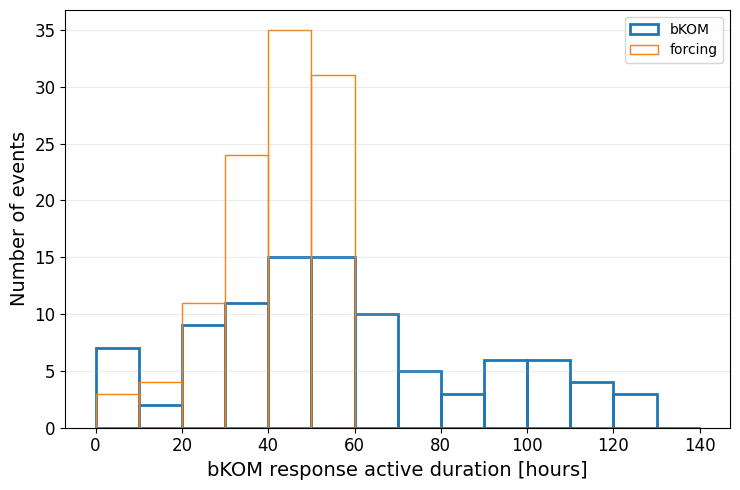

In [142]:
data = df_combined.loc[df_combined["active_duration_hr"] < 130 , "active_duration_hr"]

plt.figure(figsize=(7.5, 5))

plt.hist(data, bins=np.arange(0, 150, 10), edgecolor='C0', facecolor='none', linewidth=2, label="bKOM")
plt.hist(df_combined["forcing_duration_hr"], facecolor='none', edgecolor='C1', bins=np.arange(0,70,10), label="forcing")

plt.xlabel("bKOM response active duration [hours]", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)

plt.legend()
plt.tight_layout()
plt.show()

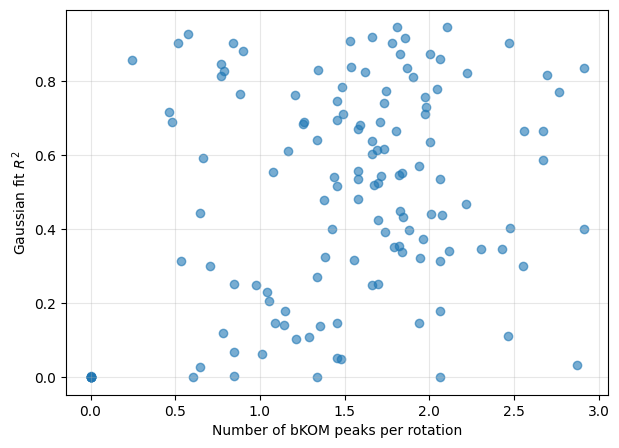

In [150]:
plt.figure(figsize=(7,5))

plt.scatter(
    df_bkom["n_peaks"]* 10 / df_bkom["fwhm_hr"],
    df_bkom["fit_r2"] ,
    alpha=0.6
)

plt.xlabel("Number of bKOM peaks per rotation")
plt.ylabel(r"Gaussian fit $R^2$")
plt.grid(alpha=0.3)

plt.show()

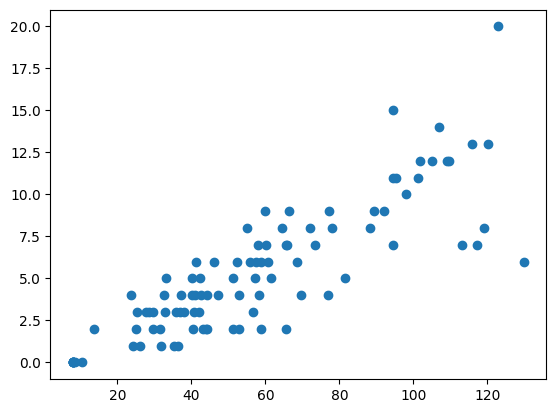

In [143]:
peaks= df_combined.loc[df_combined["active_duration_hr"]<130, "n_peaks"]
active_duration = df_combined.loc[df_combined["active_duration_hr"]<130, "active_duration_hr"]

plt.scatter(active_duration, peaks)
plt.show()